In [8]:
import sys
import pandas as pd
import numpy as np
from pathlib import Path

current_dir = Path.cwd()
proj_dir = current_dir.parent.parent.resolve()

sys.path.append(str(proj_dir))

In [9]:
from python.dualbranch.preprocessing.filter_service import FilterService
from python.dualbranch.ham10000_dataset_manager import HAM10000DatasetManager 

In [10]:
filter_service = FilterService(
    data_dir=str(proj_dir / "data")
)

dataset_manager = HAM10000DatasetManager(
    data_dir=str(proj_dir / "data")
)

In [14]:
res = filter_service.apply_texture_filters(image_id="ISIC_0024306") # , filter_list=['gabor_filter,']

In [23]:
res['gabor_filter']

array([[0.23693633, 0.21137762, 0.22033195, ..., 0.2451583 , 0.24813746,
        0.24899082],
       [0.22715145, 0.23082992, 0.24893677, ..., 0.23872235, 0.24373184,
        0.22368225],
       [0.20327903, 0.22584106, 0.23722194, ..., 0.2425889 , 0.24840513,
        0.25481796],
       ...,
       [0.20449805, 0.20833588, 0.22404112, ..., 0.22625458, 0.2348465 ,
        0.21155618],
       [0.18014127, 0.20333193, 0.20637712, ..., 0.25126785, 0.26503992,
        0.2507946 ],
       [0.18964833, 0.21486482, 0.20566103, ..., 0.25047025, 0.26839507,
        0.23875462]], shape=(450, 600), dtype=float32)

In [7]:
filter_service.save_applied_filters(res, image_id="ISIC_0024306", separate=True)

In [12]:
# create balanced dataset with 1000 samples (500 mel, 500 nv) and save to csv
dataset_manager.load_cleaned_metadata(
    filter_melanoma_only=True
)

# get all nv and mel
nv = dataset_manager.df[dataset_manager.df["dx"] == "nv"]
mel = dataset_manager.df[dataset_manager.df["dx"] == "mel"]

# sample 500 from each
nv_sample = nv.sample(n=500, random_state=42, replace=False)
mel_sample = mel.sample(n=500, random_state=42, replace=False)

# shuffle and save to csv
balanced_thousand = pd.concat([nv_sample, mel_sample])
balanced_thousand = balanced_thousand.sample(frac=1, random_state=42).reset_index(drop=True)

balanced_thousand.to_csv("HAM10000_metadata_filtered_thousand.csv", index=False)


In [11]:
dataset_manager.load_cleaned_metadata(
    filter_melanoma_only=True,
    sample_size=1000
)

print(dataset_manager.df['dx'].value_counts())

thousand_image_ids = dataset_manager.df['image_id'].tolist()

dx
nv     500
mel    500
Name: count, dtype: int64


In [11]:
dataset_manager.load_cleaned_metadata(
    filter_melanoma_only=True,
)

In [13]:
result_map = filter_service.filtered_image_generator(
    list_image_ids=dataset_manager.df['image_id'].tolist(),
    filter_list=['gabor_filter', 'lbp_filter', 'glcm_filter'],
    batch_size=10,
    asnpz=False
)

Processed 10 / 7816 images.
Processed 20 / 7816 images.
Processed 30 / 7816 images.
Processed 40 / 7816 images.
Processed 50 / 7816 images.
Processed 60 / 7816 images.
Processed 70 / 7816 images.
Processed 80 / 7816 images.
Processed 90 / 7816 images.
Processed 100 / 7816 images.
Processed 110 / 7816 images.
Processed 120 / 7816 images.
Processed 130 / 7816 images.
Processed 140 / 7816 images.
Processed 150 / 7816 images.
Processed 160 / 7816 images.
Processed 170 / 7816 images.
Processed 180 / 7816 images.
Processed 190 / 7816 images.
Processed 200 / 7816 images.
Processed 210 / 7816 images.
Processed 220 / 7816 images.
Processed 230 / 7816 images.
Processed 240 / 7816 images.
Processed 250 / 7816 images.
Processed 260 / 7816 images.
Processed 270 / 7816 images.
Processed 280 / 7816 images.
Processed 290 / 7816 images.
Processed 300 / 7816 images.
Processed 310 / 7816 images.
Processed 320 / 7816 images.
Processed 330 / 7816 images.
Processed 340 / 7816 images.
Processed 350 / 7816 im

In [27]:
filter_service.save_applied_filters_batch(
    filters_results_map=result_map
)

In [ ]:
df = pd.read_csv(
    str(proj_dir / "data" / "HAM10000_metadata_cleaned.csv"))
filtered_thousand_image_metadata = df[df["image_id"].isin(thousand_image_ids)]
filtered_thousand_image_metadata.to_csv(
    str(proj_dir / "data" / "HAM10000_metadata_filtered_thousand.csv"),
    index=False
)

In [ ]:
img = np.load(str(proj_dir / "data" / "filtered" / "ISIC_0028215.npz"))

In [ ]:
print(img['gabor_filter'])

[[0.00119036 0.00040971 0.00226006 ... 0.00498912 0.00627132 0.00472366]
 [0.00091862 0.00064804 0.00269534 ... 0.00533996 0.00580251 0.00537885]
 [0.00075732 0.00072194 0.00221816 ... 0.00587587 0.00534302 0.00597247]
 ...
 [0.0058884  0.00277858 0.0059192  ... 0.00290131 0.00102515 0.0003759 ]
 [0.00562135 0.00398375 0.0051641  ... 0.00319549 0.0011711  0.00082788]
 [0.0052011  0.00530117 0.0047166  ... 0.00264601 0.00107729 0.00143592]]


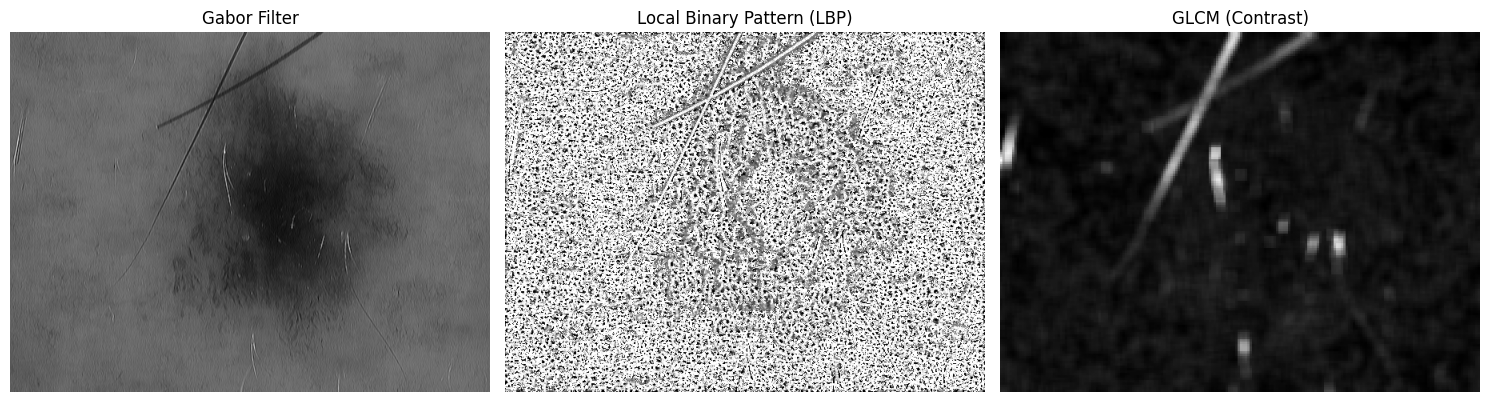

In [20]:
import matplotlib.pyplot as plt
# Create a figure with subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot Gabor filter
axes[0].imshow(res['gabor_filter'], cmap='gray')
axes[0].set_title('Gabor Filter')
axes[0].axis('off')

# Plot LBP filter
axes[1].imshow(res['lbp_filter'], cmap='gray')
axes[1].set_title('Local Binary Pattern (LBP)')
axes[1].axis('off')

# Plot GLCM filter
axes[2].imshow(res['glcm_filter'], cmap='gray')
axes[2].set_title('GLCM (Contrast)')
axes[2].axis('off')

plt.tight_layout()
plt.show()